# GUIDE Dataset — Three-Model Hybrid (Soft-Voting) Ensemble

Target: `IncidentGrade` (TruePositive / BenignPositive / FalsePositive), 3-class classification.

Scope for this notebook:
- Combine the already-trained **LightGBM**, **CatBoost**, and **XGBoost** baselines via **equal-weight soft voting** (average each class's probability across the three models, then take the argmax). Weights are fixed at 1/3 each — **no weight tuning** is performed here.
- **No model is retrained.** CatBoost and XGBoost already saved per-row validation probabilities (`val_predictions.csv`); LightGBM did not, so this notebook reloads its saved model + exact original preprocessing + the shared `split_assignment.csv` and generates its missing validation probabilities (prediction only, not training).
- All three models' row coverage, identities (`Id`/`OrgId`/`IncidentId`), and true labels are **explicitly verified to match** before any averaging — rows are aligned on a stable `row_id`, and any mismatch is raised loudly rather than silently dropped.
- Logistic Regression is included only as a **reference** from its already-saved `results.json` (no row-level probabilities were ever saved for it, and retraining it was out of scope) — its unresolved non-convergence (`max_iter` reached) is carried over and flagged again here, not re-litigated.
- The official `GUIDE_Test.csv` is **not loaded**. Every metric in this notebook is a **validation-set** metric.

In [1]:
import os, glob, time, json, warnings, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid')

OUT_DIR = '/kaggle/working'
os.makedirs(OUT_DIR, exist_ok=True)

t0 = time.time()
def lap(msg):
    print(f'[{time.time() - t0:7.1f}s] {msg}')

CLASS_ORDER = ['BenignPositive', 'FalsePositive', 'TruePositive']
TARGET = 'IncidentGrade'

## 1. Load CatBoost's and XGBoost's saved validation probabilities (no retraining)

Both were mounted here via `kernel_sources` and already saved `val_predictions.csv` with per-row class probabilities, a stable `row_id`, identities, and the true label. Both files are located by searching for a path containing the respective model name, since `kernel_sources` can mount more than one `val_predictions.csv`.

In [2]:
all_val_pred_matches = glob.glob('/kaggle/input/**/val_predictions.csv', recursive=True)
lap(f'Found {len(all_val_pred_matches)} val_predictions.csv file(s) under /kaggle/input: {all_val_pred_matches}')

cb_matches = [p for p in all_val_pred_matches if 'catboost' in p.lower()]
xgb_matches = [p for p in all_val_pred_matches if 'xgboost' in p.lower()]
if not cb_matches:
    raise FileNotFoundError('No CatBoost val_predictions.csv found — check kernel_sources includes guide-catboost-baseline')
if not xgb_matches:
    raise FileNotFoundError('No XGBoost val_predictions.csv found — check kernel_sources includes guide-xgboost-baseline')

cb_df = pd.read_csv(cb_matches[0])
lap(f'Loaded CatBoost val_predictions.csv: {cb_df.shape} from {cb_matches[0]}')
xgb_df = pd.read_csv(xgb_matches[0])
lap(f'Loaded XGBoost val_predictions.csv: {xgb_df.shape} from {xgb_matches[0]}')

for name, d in [('CatBoost', cb_df), ('XGBoost', xgb_df)]:
    expected_cols = {f'proba_{c}' for c in CLASS_ORDER} | {'row_id', 'Id', 'OrgId', 'IncidentId', 'y_true', 'y_pred'}
    missing = expected_cols - set(d.columns)
    assert not missing, f'{name} val_predictions.csv is missing expected columns: {missing}'
lap('Both files have the expected row_id/identity/proba_* columns.')

[    1.5s] Found 2 val_predictions.csv file(s) under /kaggle/input: ['/kaggle/input/notebooks/towsifhassan1132/guide-xgboost-baseline/xgboost/val_predictions.csv', '/kaggle/input/notebooks/towsifhassan1132/guide-catboost-baseline/val_predictions.csv']
[    4.7s] Loaded CatBoost val_predictions.csv: (1924585, 9) from /kaggle/input/notebooks/towsifhassan1132/guide-catboost-baseline/val_predictions.csv
[    7.2s] Loaded XGBoost val_predictions.csv: (1924585, 9) from /kaggle/input/notebooks/towsifhassan1132/guide-xgboost-baseline/xgboost/val_predictions.csv
[    7.2s] Both files have the expected row_id/identity/proba_* columns.


## 2. Generate LightGBM's missing validation probabilities

LightGBM's own notebook saved `lightgbm_model.pkl`, `preprocessing_info.json` (including the exact fitted `category_values` used for its categorical columns), and `split_assignment.csv` — but no per-row validation predictions. To include it in the ensemble, this section reproduces the **exact same cleaning, feature engineering, and categorical encoding** as the original LightGBM notebook (same column order, same fixed category lists loaded from `preprocessing_info.json` rather than re-fit, so the saved model sees inputs encoded exactly as it was trained on), then calls `predict_proba` on the validation split only. **The model itself is not refit** — this is prediction, not training.

In [3]:
matches = glob.glob('/kaggle/input/**/GUIDE_Train.csv', recursive=True)
if not matches:
    raise FileNotFoundError('GUIDE_Train.csv not found under /kaggle/input')
DATA_DIR = os.path.dirname(matches[0])
lap(f'Using DATA_DIR = {DATA_DIR}')

lgb_prep_matches = [p for p in glob.glob('/kaggle/input/**/preprocessing_info.json', recursive=True) if 'lightgbm' in p.lower()]
lgb_model_matches = [p for p in glob.glob('/kaggle/input/**/lightgbm_model.pkl', recursive=True)]
lgb_split_matches = [p for p in glob.glob('/kaggle/input/**/split_assignment.csv', recursive=True) if 'lightgbm' in p.lower()]
if not (lgb_prep_matches and lgb_model_matches and lgb_split_matches):
    raise FileNotFoundError('LightGBM preprocessing_info.json / lightgbm_model.pkl / split_assignment.csv '
                            'not all found — check kernel_sources includes guide-lightgbm-baseline')

with open(lgb_prep_matches[0]) as f:
    lgb_prep = json.load(f)
lgb_model = joblib.load(lgb_model_matches[0])
lap(f'Loaded LightGBM preprocessing_info.json ({lgb_prep_matches[0]}) and lightgbm_model.pkl ({lgb_model_matches[0]})')

LGB_CATEGORICAL_COLS = lgb_prep['categorical_cols']
LGB_NUMERIC_COLS = lgb_prep['numeric_cols']
LGB_FEATURES = LGB_CATEGORICAL_COLS + LGB_NUMERIC_COLS
LGB_CATEGORY_VALUES = lgb_prep['category_values']
LGB_TARGET_MAP = lgb_prep['target_map']
assert LGB_FEATURES == lgb_prep['features']
print('LightGBM categorical cols:', LGB_CATEGORICAL_COLS)
print('LightGBM numeric cols:', LGB_NUMERIC_COLS)

[    7.5s] Using DATA_DIR = /kaggle/input/datasets/Microsoft/microsoft-security-incident-prediction
[   11.8s] Loaded LightGBM preprocessing_info.json (/kaggle/input/notebooks/towsifhassan1132/guide-lightgbm-baseline/preprocessing_info.json) and lightgbm_model.pkl (/kaggle/input/notebooks/towsifhassan1132/guide-lightgbm-baseline/lightgbm_model.pkl)
LightGBM categorical cols: ['Category', 'EntityType', 'EvidenceRole', 'ResourceType', 'Roles', 'OSFamily', 'OSVersion', 'AntispamDirection', 'SuspicionLevel', 'LastVerdict', 'MitrePrimary']
LightGBM numeric cols: ['DetectorId', 'AlertTitle', 'CountryCode', 'State', 'City', 'Hour', 'DayOfWeek', 'MitreCount']


In [4]:
df = pd.read_csv(f'{DATA_DIR}/GUIDE_Train.csv')
lap(f'Loaded raw train = {df.shape}')

df = df.drop_duplicates().reset_index(drop=True)
df = df.dropna(subset=[TARGET]).reset_index(drop=True)
df['row_id'] = np.arange(len(df))
lap(f'After cleaning (identical steps/order to the other notebooks): {df.shape}')

DERIVED_COLS = ['Hour', 'DayOfWeek', 'MitreCount', 'MitrePrimary']
RAW_NEEDED_COLS = ['row_id', 'Id', 'OrgId', 'IncidentId', TARGET, 'Timestamp', 'MitreTechniques'] + \
    [c for c in LGB_FEATURES if c not in DERIVED_COLS]
df = df[RAW_NEEDED_COLS].copy()
gc.collect()
lap(f'Trimmed to needed raw columns: {df.shape}')

df['Timestamp'] = pd.to_datetime(df['Timestamp'], errors='coerce')
df['Hour'] = df['Timestamp'].dt.hour
df['DayOfWeek'] = df['Timestamp'].dt.dayofweek
mitre = df['MitreTechniques'].fillna('')
df['MitreCount'] = mitre.apply(lambda s: 0 if s == '' else len(s.split(';')))
df['MitrePrimary'] = mitre.apply(lambda s: s.split(';')[0] if s != '' else 'None')
lap('Feature engineering done (Hour/DayOfWeek/MitreCount/MitrePrimary).')

[   74.6s] Loaded raw train = (9516837, 45)
[  122.5s] After cleaning (identical steps/order to the other notebooks): (9442956, 46)
[  126.4s] Trimmed to needed raw columns: (9442956, 22)
[  142.0s] Feature engineering done (Hour/DayOfWeek/MitreCount/MitrePrimary).


In [5]:
n_unseen_total = 0
for col in LGB_CATEGORICAL_COLS:
    df[col] = df[col].fillna('Missing').astype(str)
    df[col] = pd.Categorical(df[col], categories=LGB_CATEGORY_VALUES[col])
    n_unseen = df[col].isna().sum()
    n_unseen_total += n_unseen
    if n_unseen > 0:
        print(f'  {col}: {n_unseen} rows have a value outside the saved training category list -> missing')
lap(f'Applied LightGBM\'s saved (not re-fit) category lists; {n_unseen_total} total unseen-category cells')

for col in LGB_NUMERIC_COLS:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df['_target'] = df[TARGET].map(LGB_TARGET_MAP)
assert df['_target'].notna().all()

split_assignment = pd.read_csv(lgb_split_matches[0], usecols=['Id', 'split'])
n_id_conflicts = split_assignment.groupby('Id')['split'].nunique().gt(1).sum()
assert n_id_conflicts == 0
split_lookup = split_assignment.drop_duplicates(subset=['Id']).set_index('Id')['split']
del split_assignment
gc.collect()

before_rows = len(df)
df['split'] = df['Id'].map(split_lookup)
assert df['split'].notna().all(), 'Row alignment check failed against LightGBM split_assignment.csv'
assert len(df) == before_rows

group_key = df['OrgId'].astype(str) + '_' + df['IncidentId'].astype(str)
train_groups = set(group_key[df['split'] == 'train'])
val_groups = set(group_key[df['split'] == 'val'])
assert len(train_groups & val_groups) == 0, 'Group leakage between train and validation!'
lap('Row alignment + zero group overlap verified against split_assignment.csv.')

val_mask = df['split'] == 'val'
X_val_lgb = df.loc[val_mask, LGB_FEATURES]
y_val_lgb = df.loc[val_mask, '_target']
lgb_row_ids = df.loc[val_mask, ['row_id', 'Id', 'OrgId', 'IncidentId']].reset_index(drop=True)
lap(f'X_val_lgb={X_val_lgb.shape}')

[  162.7s] Applied LightGBM's saved (not re-fit) category lists; 0 total unseen-category cells
[  179.9s] Row alignment + zero group overlap verified against split_assignment.csv.
[  181.1s] X_val_lgb=(1924585, 19)


In [6]:
lgb_predict_start = time.time()
lgb_proba_arr = lgb_model.predict_proba(X_val_lgb)
lgb_pred_arr = lgb_model.predict(X_val_lgb)
lgb_prediction_time = time.time() - lgb_predict_start
lap(f'LightGBM predict_proba on validation split done in {lgb_prediction_time:.1f}s (no retraining)')

inv_lgb_target_map = {v: k for k, v in LGB_TARGET_MAP.items()}
lgb_model_classes_as_names = [inv_lgb_target_map[c] for c in lgb_model.classes_]
print('LightGBM model.classes_ as names (column order of predict_proba output):', lgb_model_classes_as_names)

lgb_df = lgb_row_ids.copy()
for i, cls in enumerate(lgb_model_classes_as_names):
    lgb_df[f'proba_{cls}'] = lgb_proba_arr[:, i]
lgb_df['y_true'] = y_val_lgb.reset_index(drop=True).map(inv_lgb_target_map)
lgb_df['y_pred'] = pd.Series(lgb_pred_arr).map(inv_lgb_target_map)

lgb_sanity_acc = accuracy_score(lgb_df['y_true'], lgb_df['y_pred'])
print(f'Sanity check — regenerated LightGBM validation accuracy: {lgb_sanity_acc:.4f} '
      f'(original notebook reported 0.806)')

lgb_df.to_csv(f'{OUT_DIR}/lightgbm_val_predictions.csv', index=False)
lap('Saved lightgbm_val_predictions.csv (generated here, not by the original LightGBM notebook)')
del df, X_val_lgb
gc.collect()

[  565.0s] LightGBM predict_proba on validation split done in 384.0s (no retraining)
LightGBM model.classes_ as names (column order of predict_proba output): ['BenignPositive', 'FalsePositive', 'TruePositive']
Sanity check — regenerated LightGBM validation accuracy: 0.8060 (original notebook reported 0.806)
[  582.5s] Saved lightgbm_val_predictions.csv (generated here, not by the original LightGBM notebook)


0

## 3. Align all three models' predictions and verify they agree before averaging

Rows are merged on `row_id`. Per the task's explicit requirement, this does **not** silently inner-join and drop mismatches: it first asserts the three `row_id` sets are identical, then asserts that `Id`/`OrgId`/`IncidentId`/`y_true` agree pairwise across every merged row. Any disagreement raises an error here rather than being silently dropped.

In [7]:
lgb_ids, cb_ids, xgb_ids = set(lgb_df['row_id']), set(cb_df['row_id']), set(xgb_df['row_id'])
if not (lgb_ids == cb_ids == xgb_ids):
    raise AssertionError(
        f'row_id sets differ between models — refusing to silently drop rows. '
        f'LightGBM\u2229CatBoost only: {len(lgb_ids - cb_ids)} LGB-only, {len(cb_ids - lgb_ids)} CB-only; '
        f'LightGBM\u2229XGBoost only: {len(lgb_ids - xgb_ids)} LGB-only, {len(xgb_ids - lgb_ids)} XGB-only'
    )
lap(f'row_id sets identical across all three models: {len(lgb_ids)} validation rows each')

merged = lgb_df.merge(cb_df, on='row_id', suffixes=('_lgb', '_cb'))
merged = merged.merge(xgb_df, on='row_id', suffixes=('', '_xgb'))
assert len(merged) == len(lgb_ids), 'Merge changed row count unexpectedly'

for col in ['Id', 'OrgId', 'IncidentId']:
    assert (merged[f'{col}_lgb'] == merged[f'{col}_cb']).all(), f'{col} mismatch between LightGBM and CatBoost rows'
    assert (merged[f'{col}_lgb'] == merged[col]).all(), f'{col} mismatch between LightGBM and XGBoost rows'
assert (merged['y_true_lgb'] == merged['y_true_cb']).all(), 'y_true mismatch between LightGBM and CatBoost'
assert (merged['y_true_lgb'] == merged['y_true']).all(), 'y_true mismatch between LightGBM and XGBoost'
lap('Verified: identical Id/OrgId/IncidentId/y_true across all three models for every merged row.')

for name, d in [('LightGBM', lgb_df), ('CatBoost', cb_df), ('XGBoost', xgb_df)]:
    cols_found = {c.replace('proba_', '') for c in d.columns if c.startswith('proba_')}
    assert cols_found == set(CLASS_ORDER), f'{name} class-probability columns {cols_found} != expected {set(CLASS_ORDER)}'
lap('Verified: all three models expose the same 3 class-probability columns.')

y_true = merged['y_true_lgb'].reset_index(drop=True)
row_identity = merged[['row_id', 'Id_lgb', 'OrgId_lgb', 'IncidentId_lgb']].rename(
    columns={'Id_lgb': 'Id', 'OrgId_lgb': 'OrgId', 'IncidentId_lgb': 'IncidentId'}).reset_index(drop=True)

[  584.0s] row_id sets identical across all three models: 1924585 validation rows each
[  584.9s] Verified: identical Id/OrgId/IncidentId/y_true across all three models for every merged row.
[  584.9s] Verified: all three models expose the same 3 class-probability columns.


## 4. Equal-weight soft voting

`hybrid_proba[class] = mean(lightgbm_proba[class], catboost_proba[class], xgboost_proba[class])` for each of the 3 classes, weight 1/3 each. Prediction = `argmax` over the averaged probabilities. No weight search is performed.

In [8]:
WEIGHTS = {'lightgbm': 1/3, 'catboost': 1/3, 'xgboost': 1/3}

lgb_proba = merged[[f'proba_{c}_lgb' for c in CLASS_ORDER]].to_numpy()
cb_proba = merged[[f'proba_{c}_cb' for c in CLASS_ORDER]].to_numpy()
xgb_proba = merged[[f'proba_{c}' for c in CLASS_ORDER]].to_numpy()

combine_start = time.time()
hybrid_proba = WEIGHTS['lightgbm'] * lgb_proba + WEIGHTS['catboost'] * cb_proba + WEIGHTS['xgboost'] * xgb_proba
hybrid_pred_idx = hybrid_proba.argmax(axis=1)
hybrid_pred = np.array(CLASS_ORDER)[hybrid_pred_idx]
combination_time = time.time() - combine_start
lap(f'Soft-voting combination done in {combination_time:.4f}s for {len(hybrid_pred)} rows')

lgb_pred_own = np.array(CLASS_ORDER)[lgb_proba.argmax(axis=1)]
cb_pred_own = np.array(CLASS_ORDER)[cb_proba.argmax(axis=1)]
xgb_pred_own = np.array(CLASS_ORDER)[xgb_proba.argmax(axis=1)]

[  585.1s] Soft-voting combination done in 0.1228s for 1924585 rows


## 5. Evaluate hybrid vs. each individual model (all on this exact aligned validation subset)

Each individual model's metrics are recomputed here directly from its own probability columns on the identical aligned row set used for the hybrid — this is an apples-to-apples check, not a re-quote of each notebook's own `results.json` (though they should closely match, since row coverage was just verified to be identical).

In [9]:
def eval_model(name, y_pred_arr):
    acc = accuracy_score(y_true, y_pred_arr)
    macro_f1 = f1_score(y_true, y_pred_arr, average='macro')
    weighted_f1 = f1_score(y_true, y_pred_arr, average='weighted')
    report = classification_report(y_true, y_pred_arr, labels=CLASS_ORDER, target_names=CLASS_ORDER, output_dict=True)
    return {'model': name, 'accuracy': round(float(acc), 4), 'macro_f1': round(float(macro_f1), 4),
            'weighted_f1': round(float(weighted_f1), 4),
            'TruePositive_recall': round(float(report['TruePositive']['recall']), 4),
            'source': 'recomputed on aligned validation subset'}, report

rows_summary = []
reports = {}
for name, preds in [('LightGBM', lgb_pred_own), ('CatBoost', cb_pred_own),
                     ('XGBoost', xgb_pred_own), ('Hybrid (soft voting)', hybrid_pred)]:
    summary, report = eval_model(name, preds)
    rows_summary.append(summary)
    reports[name] = report
    print(f"{name}: accuracy={summary['accuracy']}  macro_f1={summary['macro_f1']}  "
          f"weighted_f1={summary['weighted_f1']}  TruePositive_recall={summary['TruePositive_recall']}")

logreg_results_matches = [p for p in glob.glob('/kaggle/input/**/results.json', recursive=True) if 'logreg' in p.lower()]
logreg_row = None
if logreg_results_matches:
    with open(logreg_results_matches[0]) as f:
        logreg_results = json.load(f)
    logreg_row = {
        'model': 'Logistic Regression (reference only, non-converged)' if not logreg_results.get('converged', True)
                  else 'Logistic Regression (reference only)',
        'accuracy': logreg_results['accuracy'], 'macro_f1': logreg_results['macro_f1'],
        'weighted_f1': logreg_results['weighted_f1'],
        'TruePositive_recall': round(logreg_results['per_class_report']['TruePositive']['recall'], 4),
        'source': 'reference only, from its own saved results.json (not row-level merged; no retraining)',
    }
    rows_summary.append(logreg_row)
    print('Logistic Regression reference row added from its saved results.json (not mounted via kernel_sources '
          'for this notebook, so only included if its results.json happened to be reachable under /kaggle/input).')
else:
    lap('Logistic Regression results.json not found under /kaggle/input (its kernel is not in kernel_sources '
        'for this ensemble notebook) — omitted from the comparison table rather than guessed.')

comparison_df = pd.DataFrame(rows_summary)
print(comparison_df)

LightGBM: accuracy=0.806  macro_f1=0.7879  weighted_f1=0.8019  TruePositive_recall=0.7748
CatBoost: accuracy=0.811  macro_f1=0.7946  weighted_f1=0.8074  TruePositive_recall=0.7748
XGBoost: accuracy=0.8062  macro_f1=0.7885  weighted_f1=0.8014  TruePositive_recall=0.7707
Hybrid (soft voting): accuracy=0.8173  macro_f1=0.8013  weighted_f1=0.8134  TruePositive_recall=0.7803
Logistic Regression reference row added from its saved results.json (not mounted via kernel_sources for this notebook, so only included if its results.json happened to be reachable under /kaggle/input).
                                               model  accuracy  macro_f1  \
0                                           LightGBM    0.8060    0.7879   
1                                           CatBoost    0.8110    0.7946   
2                                            XGBoost    0.8062    0.7885   
3                               Hybrid (soft voting)    0.8173    0.8013   
4  Logistic Regression (reference only, non-

## 6. Charts

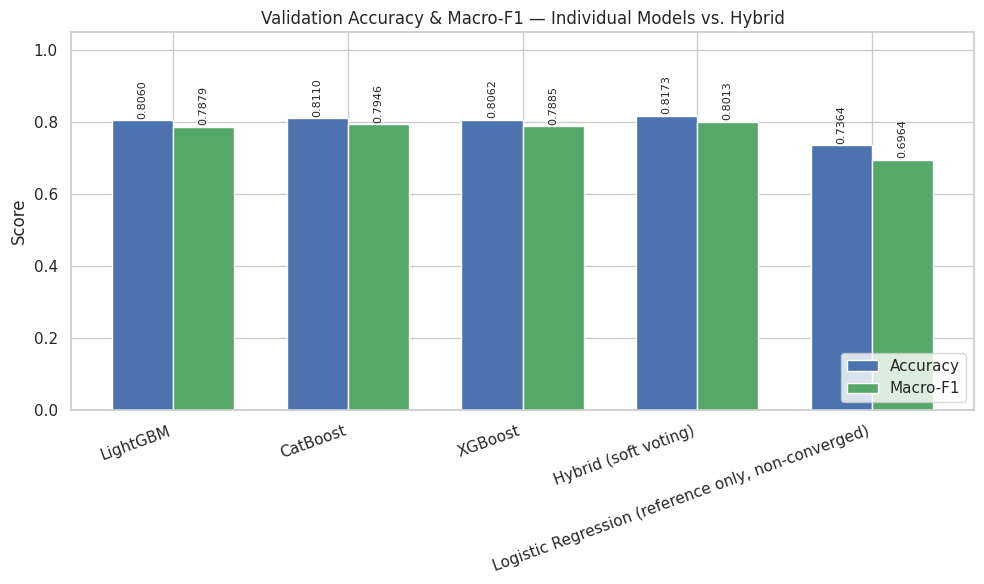

In [10]:
plot_df = comparison_df[comparison_df['model'].isin(
    ['LightGBM', 'CatBoost', 'XGBoost', 'Hybrid (soft voting)'] +
    ([logreg_row['model']] if logreg_row else [])
)].copy()
x = np.arange(len(plot_df))
width = 0.35
fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(x - width/2, plot_df['accuracy'], width, label='Accuracy', color='#4C72B0')
ax.bar(x + width/2, plot_df['macro_f1'], width, label='Macro-F1', color='#55A868')
ax.set_xticks(x)
ax.set_xticklabels(plot_df['model'], rotation=20, ha='right')
ax.set_ylim(0, 1.05)
ax.set_ylabel('Score')
ax.set_title('Validation Accuracy & Macro-F1 — Individual Models vs. Hybrid')
for i, (a, m) in enumerate(zip(plot_df['accuracy'], plot_df['macro_f1'])):
    ax.text(i - width/2, a + 0.01, f'{a:.4f}', ha='center', fontsize=8, rotation=90)
    ax.text(i + width/2, m + 0.01, f'{m:.4f}', ha='center', fontsize=8, rotation=90)
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/model_comparison.png', dpi=150)
plt.show()

/tmp/ipykernel_16/1638316239.py:3: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(plot_df['model'], rotation=20, ha='right')


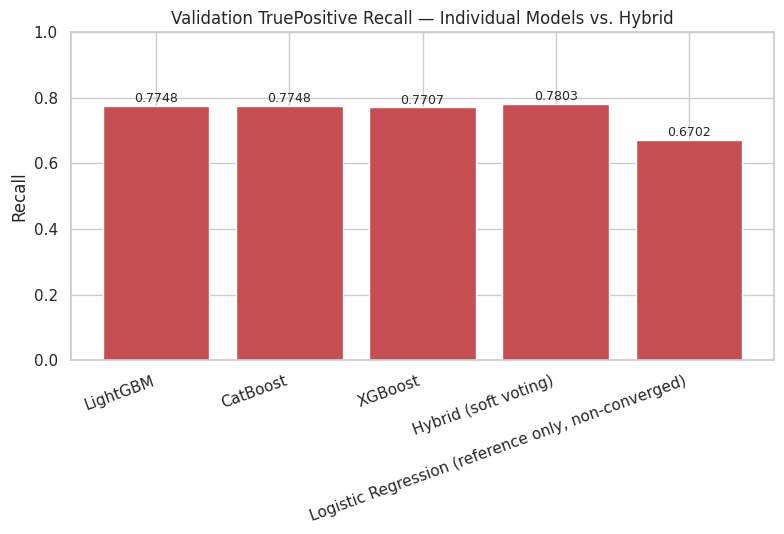

In [11]:
fig, ax = plt.subplots(figsize=(8, 5.5))
bars = ax.bar(plot_df['model'], plot_df['TruePositive_recall'], color='#C44E52')
ax.set_xticklabels(plot_df['model'], rotation=20, ha='right')
ax.set_ylim(0, 1.0)
ax.set_ylabel('Recall')
ax.set_title('Validation TruePositive Recall — Individual Models vs. Hybrid')
for bar, val in zip(bars, plot_df['TruePositive_recall']):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.012, f'{val:.4f}', ha='center', fontsize=9)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/truepositive_recall_comparison.png', dpi=150)
plt.show()

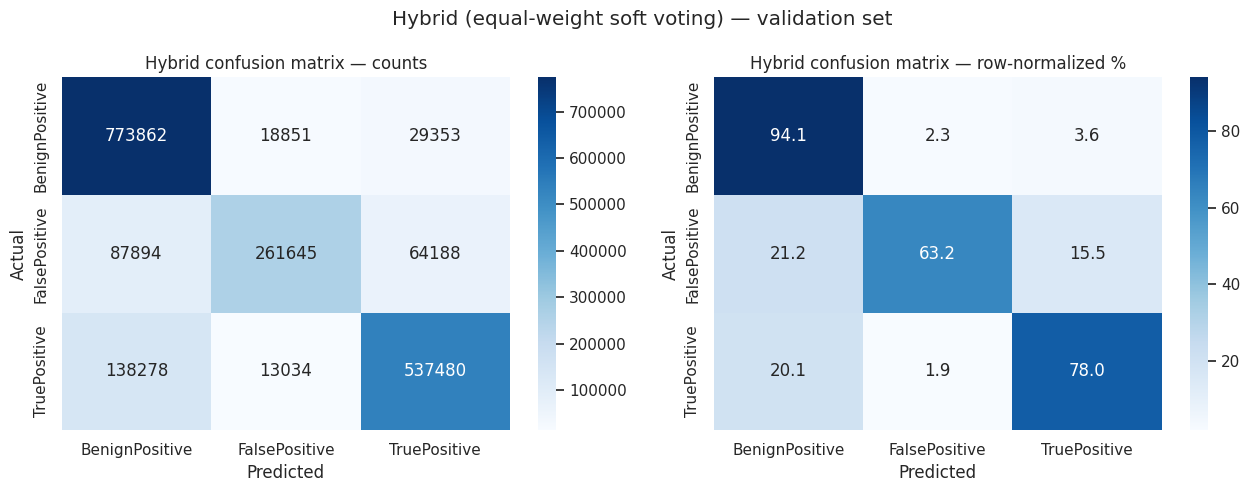

In [12]:
cm = confusion_matrix(y_true, hybrid_pred, labels=CLASS_ORDER)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_ORDER, yticklabels=CLASS_ORDER, ax=axes[0])
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual'); axes[0].set_title('Hybrid confusion matrix — counts')
sns.heatmap(cm_pct, annot=True, fmt='.1f', cmap='Blues', xticklabels=CLASS_ORDER, yticklabels=CLASS_ORDER, ax=axes[1])
axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('Actual'); axes[1].set_title('Hybrid confusion matrix — row-normalized %')
fig.suptitle('Hybrid (equal-weight soft voting) — validation set')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/hybrid_confusion_matrix.png', dpi=120)
plt.show()

## 7. Save comparison.csv, results.json, hybrid predictions/probabilities, weights, and class order

In [13]:
comparison_df.to_csv(f'{OUT_DIR}/comparison.csv', index=False)

hybrid_report = classification_report(y_true, hybrid_pred, labels=CLASS_ORDER, target_names=CLASS_ORDER, output_dict=True)
with open(f'{OUT_DIR}/classification_report.json', 'w') as f:
    json.dump(hybrid_report, f, indent=2)

with open(f'{OUT_DIR}/weights.json', 'w') as f:
    json.dump({'weights': WEIGHTS, 'method': 'equal-weight soft voting (no tuning performed)',
                'class_order': CLASS_ORDER}, f, indent=2)

hybrid_predictions = row_identity.copy()
for i, cls in enumerate(CLASS_ORDER):
    hybrid_predictions[f'lightgbm_proba_{cls}'] = lgb_proba[:, i]
    hybrid_predictions[f'catboost_proba_{cls}'] = cb_proba[:, i]
    hybrid_predictions[f'xgboost_proba_{cls}'] = xgb_proba[:, i]
    hybrid_predictions[f'hybrid_proba_{cls}'] = hybrid_proba[:, i]
hybrid_predictions['y_true'] = y_true.values
hybrid_predictions['hybrid_y_pred'] = hybrid_pred
hybrid_predictions.to_csv(f'{OUT_DIR}/hybrid_val_predictions.csv', index=False)

accuracy = accuracy_score(y_true, hybrid_pred)
macro_f1 = f1_score(y_true, hybrid_pred, average='macro')
weighted_f1 = f1_score(y_true, hybrid_pred, average='weighted')

results = {
    'evaluation_set': 'validation (held-out split from guide-lightgbm-baseline, NOT the official test set)',
    'n_validation_rows': int(len(y_true)),
    'ensemble_method': 'equal-weight soft voting (average class probabilities, argmax)',
    'weights': WEIGHTS,
    'class_order': CLASS_ORDER,
    'lightgbm_prediction_time_seconds': round(lgb_prediction_time, 2),
    'ensemble_combination_time_seconds': round(combination_time, 4),
    'accuracy': round(float(accuracy), 4),
    'macro_f1': round(float(macro_f1), 4),
    'weighted_f1': round(float(weighted_f1), 4),
    'per_class_report': hybrid_report,
    'confusion_matrix': cm.tolist(),
    'comparison_table': comparison_df.to_dict(orient='records'),
    'no_retraining_performed': True,
    'logistic_regression_included_as_row_level_ensemble_member': False,
}
with open(f'{OUT_DIR}/results.json', 'w') as f:
    json.dump(results, f, indent=2)

lap('Saved comparison.csv, results.json, classification_report.json, weights.json, '
    'hybrid_val_predictions.csv, lightgbm_val_predictions.csv, and 3 PNG charts')
print(json.dumps({k: v for k, v in results.items() if k not in ('per_class_report', 'confusion_matrix', 'comparison_table')}, indent=2))

[  787.8s] Saved comparison.csv, results.json, classification_report.json, weights.json, hybrid_val_predictions.csv, lightgbm_val_predictions.csv, and 3 PNG charts
{
  "evaluation_set": "validation (held-out split from guide-lightgbm-baseline, NOT the official test set)",
  "n_validation_rows": 1924585,
  "ensemble_method": "equal-weight soft voting (average class probabilities, argmax)",
  "weights": {
    "lightgbm": 0.3333333333333333,
    "catboost": 0.3333333333333333,
    "xgboost": 0.3333333333333333
  },
  "class_order": [
    "BenignPositive",
    "FalsePositive",
    "TruePositive"
  ],
  "lightgbm_prediction_time_seconds": 383.98,
  "ensemble_combination_time_seconds": 0.1228,
  "accuracy": 0.8173,
  "macro_f1": 0.8013,
  "weighted_f1": 0.8134,
  "no_retraining_performed": true,
  "logistic_regression_included_as_row_level_ensemble_member": false
}


## 8. Summary & limitations

- **No model was retrained.** CatBoost and XGBoost contributed their own already-saved validation probabilities unchanged; LightGBM's validation probabilities were generated here by reloading its saved model and reapplying its exact original preprocessing (same cleaning order, same feature engineering, same fixed category lists loaded from its own `preprocessing_info.json` rather than re-fit) — this is prediction only.
- Row alignment across all three models was **explicitly verified**, not assumed: identical `row_id` sets, and identical `Id`/`OrgId`/`IncidentId`/`y_true` for every merged row. No rows were silently dropped.
- The ensemble is **equal-weight soft voting** (1/3 each). No weight search, stacking, or meta-learner was used — that is future work, not this notebook's scope.
- Logistic Regression appears only as a **reference row** pulled from its own saved `results.json`, not merged into the ensemble at the row level (no per-row probabilities were ever saved for it, and retraining it was out of scope). Its `max_iter`-reached non-convergence is unresolved and is labeled explicitly in the comparison table/chart rather than hidden.
- All metrics in this notebook are **validation-set** metrics on the shared split from `guide-lightgbm-baseline`. The official `GUIDE_Test.csv` was never loaded.
- Whether the hybrid actually beats every individual model is an empirical question answered by `results.json`/`comparison.csv` — it was not assumed going in, and equal weighting is not guaranteed to be optimal even if the hybrid does improve on some metrics.